# Bài tập 2 - Hồng Sen

Môn 121036. Người phụ trách: **Hồng Sen**.

Hoàn thành nội bộ: **18/11/2026**. Hạn nộp: **20/11/2026**.

Bộ khung chưa có thuật toán hoặc kết quả thực nghiệm. Đọc `README.md`, đề Bài tập 2 và bảng phân công của nhóm.

## 0. Chuẩn bị môi trường

Cell bên dưới do Codex tạo để import thư viện và xác định đường dẫn, ngoài phần cài đặt thuật toán. Các cell cài đặt được để trống.

**Khai báo AI cho cell chuẩn bị**

- Công cụ: Codex (OpenAI).
- Mục đích: tạo bộ khung thư mục, notebook và đường dẫn dùng chung.
- Prompt nguyên văn:

> giờ bạn tạo cái sườn giúp tôi [https://github.com/NguyenTanHiep07/xla-121036](https://github.com/NguyenTanHiep07/xla-121036) làm tiếp trong này cho dễ nha tạo mấy thư mục mấy cũ ko liên quan á bỏ qua

In [17]:
from pathlib import Path
from functools import partial
import math
import time
import cv2

import numpy as np
import matplotlib.pyplot as plt

REPO_DIR = Path(r"C:\xla-121036-main")

BT2_DIR = REPO_DIR / "bai_tap_2"
IMAGES_DIR = REPO_DIR / "images"
image_path = IMAGES_DIR / "uneven_lighting.jpg"

assert REPO_DIR.is_dir(), f"Repository not found: {REPO_DIR}"
assert BT2_DIR.is_dir(), f"Folder not found: {BT2_DIR}"
assert IMAGES_DIR.is_dir(), f"Folder not found: {IMAGES_DIR}"

print("REPO_DIR:", REPO_DIR)
print("BT2_DIR:", BT2_DIR)
print("IMAGES_DIR:", IMAGES_DIR)
print("Image exists:", image_path.is_file())

REPO_DIR: C:\xla-121036-main
BT2_DIR: C:\xla-121036-main\bai_tap_2
IMAGES_DIR: C:\xla-121036-main\images
Image exists: True


## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `region_growing_classic(img, seeds, T, order="stack")`

order: stack hoặc queue. Trả labels int32, -1 cho pixel chưa thuộc vùng nào.

In [21]:
def region_growing_classic(img, seeds, T, order="stack"):
    """
    Region Growing cổ điển.

    Parameters
    ----------
    img : ndarray
        Ảnh xám 2 chiều.
    seeds : iterable
        Danh sách tọa độ (row, col).
    T : float
        Ngưỡng chênh lệch cường độ.
    order : str
        "stack" (LIFO) hoặc "queue" (FIFO).

    Returns
    -------
    labels : ndarray, dtype=int32
        Nhãn vùng; -1 là pixel chưa được gán.
    """
    img = np.asarray(img, dtype=np.float64)

    if img.ndim != 2:
        raise ValueError("img phải là ảnh xám 2 chiều.")

    if not np.isfinite(img).all():
        raise ValueError("img không được chứa NaN hoặc Inf.")

    if not np.isscalar(T) or not np.isfinite(T) or T < 0:
        raise ValueError("T phải là số hữu hạn không âm.")

    if order not in ("stack", "queue"):
        raise ValueError("order chỉ nhận 'stack' hoặc 'queue'.")

    height, width = img.shape
    labels = np.full((height, width), -1, dtype=np.int32)

    seeds = [(int(r), int(c)) for r, c in seeds]

    if len(set(seeds)) != len(seeds):
        raise ValueError("Các seed không được trùng nhau.")

    for r, c in seeds:
        if not (0 <= r < height and 0 <= c < width):
            raise ValueError(f"Seed {(r, c)} nằm ngoài ảnh.")

    # Lân cận 4 hướng.
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for region_id, (sr, sc) in enumerate(seeds):

        # Bỏ qua seed đã thuộc vùng được xử lý trước đó.
        if labels[sr, sc] != -1:
            continue

        labels[sr, sc] = region_id

        frontier = [(sr, sc)]
        head = 0

        region_sum = float(img[sr, sc])
        region_count = 1
        region_mean = region_sum

        while (frontier if order == "stack" else head < len(frontier)):

            if order == "stack":
                r, c = frontier.pop()
            else:
                r, c = frontier[head]
                head += 1

            for dr, dc in neighbors:
                nr, nc = r + dr, c + dc

                if not (0 <= nr < height and 0 <= nc < width):
                    continue

                if labels[nr, nc] != -1:
                    continue

                if abs(float(img[nr, nc]) - region_mean) <= T:
                    labels[nr, nc] = region_id

                    frontier.append((nr, nc))

                    region_sum += float(img[nr, nc])
                    region_count += 1
                    region_mean = region_sum / region_count

    return labels

### `seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3)`

Trả bản đồ tần suất đổi nhãn khi nhiễu vị trí hạt giống, theo định nghĩa đề.

In [24]:
def seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3):
    if n_trials <= 0:
        raise ValueError("n_trials phải lớn hơn 0.")
    if jitter < 0:
        raise ValueError("jitter không được âm.")

    img = np.asarray(img)
    seeds = np.asarray(seeds, dtype=np.int32)

    if img.ndim < 2:
        raise ValueError("Ảnh phải có ít nhất 2 chiều.")
    if seeds.ndim != 2 or seeds.shape[1] != 2 or len(seeds) == 0:
        raise ValueError("seeds phải có dạng danh sách (row, col).")

    height, width = img.shape[:2]

    if np.any(seeds[:, 0] < 0) or np.any(seeds[:, 0] >= height):
        raise ValueError("Seed có tọa độ row ngoài ảnh.")
    if np.any(seeds[:, 1] < 0) or np.any(seeds[:, 1] >= width):
        raise ValueError("Seed có tọa độ col ngoài ảnh.")
    if len(np.unique(seeds, axis=0)) != len(seeds):
        raise ValueError("Các seed ban đầu không được trùng nhau.")

    def get_labels(result):
        if isinstance(result, tuple):
            result = result[0]
        result = np.asarray(result)

        if result.shape != (height, width):
            raise ValueError("segment_fn phải trả về bản đồ nhãn H x W.")

        return result

    baseline = get_labels(segment_fn(img, seeds.tolist()))

    changed_count = np.zeros((height, width), dtype=np.float32)
    rng = np.random.default_rng()

    for trial in range(n_trials):
        perturbed_seeds = []
        used_positions = set()

        for seed in seeds:
            row, col = map(int, seed)
            chosen_seed = None

            for attempt in range(100):
                dr = int(rng.integers(-jitter, jitter + 1))
                dc = int(rng.integers(-jitter, jitter + 1))

                new_row = int(np.clip(row + dr, 0, height - 1))
                new_col = int(np.clip(col + dc, 0, width - 1))

                candidate = (new_row, new_col)

                if candidate not in used_positions:
                    chosen_seed = candidate
                    break

            if chosen_seed is None:
                candidate = (row, col)
                if candidate not in used_positions:
                    chosen_seed = candidate
                else:
                    raise ValueError("Không tạo được các seed riêng biệt.")

            perturbed_seeds.append(chosen_seed)
            used_positions.add(chosen_seed)

        trial_labels = get_labels(
            segment_fn(img, perturbed_seeds)
        )

        changed_count += (trial_labels != baseline)

    sensitivity_map = changed_count / n_trials

    return sensitivity_map.astype(np.float32)

## Chạy thử Vòng 1 (ngoài phần cài đặt)

Các cell dưới đây chỉ chạy thử và kiểm tra hai hàm ở trên, không thuộc phần "Cài đặt - KHÔNG dùng AI".

Image shape: (480, 640)
Image dtype: uint8
Intensity range: 0 - 255


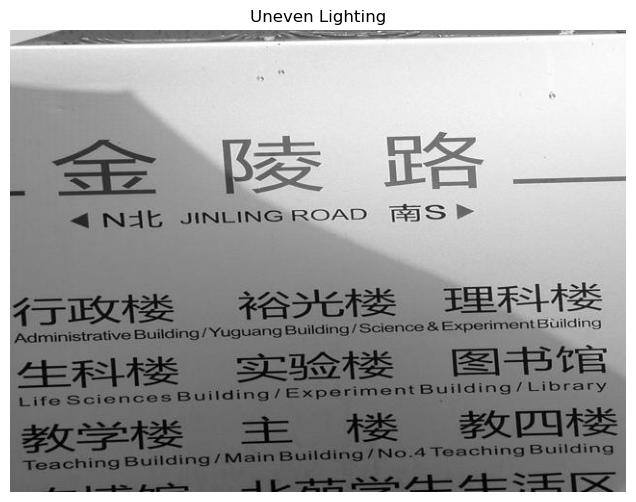

In [19]:
test_img = cv2.imread(
    str(image_path),
    cv2.IMREAD_GRAYSCALE
)

if test_img is None:
    raise FileNotFoundError(str(image_path))

print("Image shape:", test_img.shape)
print("Image dtype:", test_img.dtype)
print("Intensity range:", test_img.min(), "-", test_img.max())

plt.figure(figsize=(8, 6))
plt.imshow(test_img, cmap="gray")
plt.title("Uneven Lighting")
plt.axis("off")
plt.show()

Số pixel mỗi nhãn: {-1: 188647, 0: 56298, 1: 62255}


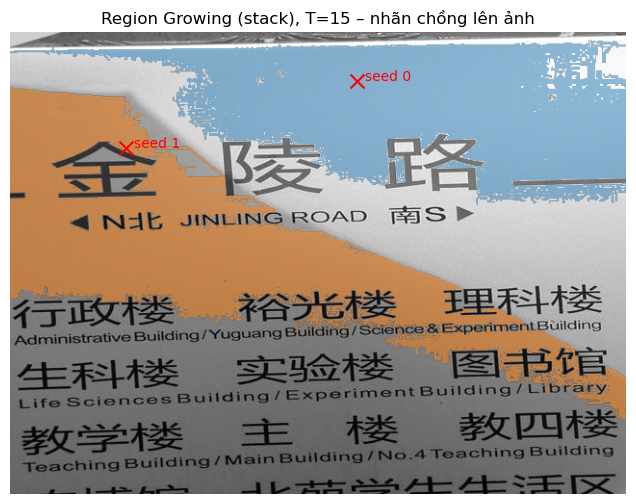

In [22]:
test_seeds = [
    (50, 360),   # nền sáng phía trên, cường độ 234
    (120, 120),  # vùng bóng phía trái, cường độ 152
]
T_test = 15

labels = region_growing_classic(test_img, test_seeds, T=T_test, order="stack")
print("Số pixel mỗi nhãn:", {k: int((labels == k).sum()) for k in (-1, 0, 1)})

plt.figure(figsize=(9, 6))
plt.imshow(test_img, cmap="gray")
plt.imshow(np.ma.masked_less(labels, 0), cmap="tab10", alpha=0.5, vmin=0, vmax=9)
for i, (r, c) in enumerate(test_seeds):
    plt.scatter(c, r, marker="x", s=100, c="red")
    plt.text(c + 8, r, f"seed {i}", color="red")
plt.title(f"Region Growing (stack), T={T_test} – nhãn chồng lên ảnh")
plt.axis("off")
plt.show()

Kích thước ảnh: (480, 640)
Số pixel khác nhau: 22995
Tỷ lệ pixel khác nhau (%): 7.485351562500001


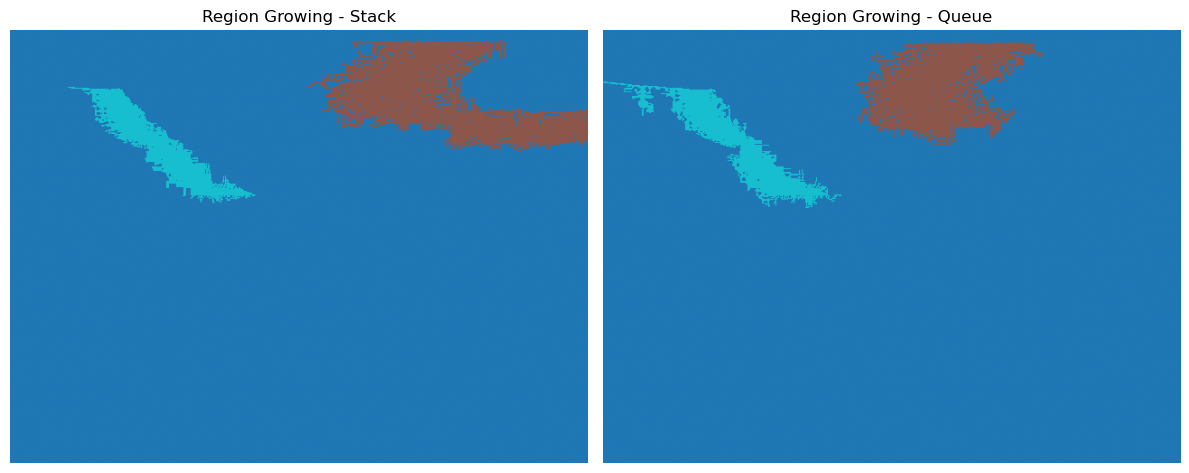

In [25]:
labels_stack = region_growing_classic(
 test_img, test_seeds, T=5, order="stack"
)
labels_queue = region_growing_classic(
 test_img, test_seeds, T=5, order="queue"
)
different_pixels = np.sum(labels_stack != labels_queue)
different_percent = different_pixels / labels_stack.size * 100
print("Kích thước ảnh:", test_img.shape)
print("Số pixel khác nhau:", different_pixels)
print("Tỷ lệ pixel khác nhau (%):", different_percent)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(labels_stack, cmap="tab10")
axes[0].set_title("Region Growing - Stack")
axes[0].axis("off")
axes[1].imshow(labels_queue, cmap="tab10")
axes[1].set_title("Region Growing - Queue")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [26]:
print("=== KIỂM TRA REGION GROWING ===")
print("Stack - shape:", labels_stack.shape)
print("Stack - dtype:", labels_stack.dtype)
print("Queue - shape:", labels_queue.shape)
print("Queue - dtype:", labels_queue.dtype)
print("Stack - số nhãn:", np.unique(labels_stack))
print("Queue - số nhãn:", np.unique(labels_queue))
assert labels_stack.shape == test_img.shape
assert labels_queue.shape == test_img.shape
assert labels_stack.dtype == np.int32
assert labels_queue.dtype == np.int32
print("Kiểm tra Region Growing: PASS")

=== KIỂM TRA REGION GROWING ===
Stack - shape: (480, 640)
Stack - dtype: int32
Queue - shape: (480, 640)
Queue - dtype: int32
Stack - số nhãn: [-1  0  1]
Queue - số nhãn: [-1  0  1]
Kiểm tra Region Growing: PASS


Kích thước: (64, 64)
Giá trị nhỏ nhất: 0.0
Giá trị lớn nhất: 0.85


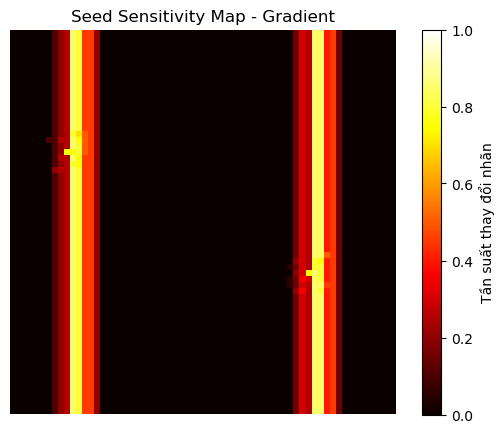

In [27]:
# Tạo ảnh Gradient 64 x 64
gradient_img = np.tile(
 np.linspace(0, 255, 64, dtype=np.uint8),
    (64, 1)
)
gradient_seeds = [(20, 10), (40, 50)]
segment_gradient = partial(
 region_growing_classic,
 T=5,
 order="stack"
)
sensitivity_gradient = seed_sensitivity(
 gradient_img,
 gradient_seeds,
 segment_gradient,
 n_trials=20,
 jitter=3
)
print("Kích thước:", sensitivity_gradient.shape)
print("Giá trị nhỏ nhất:", sensitivity_gradient.min())
print("Giá trị lớn nhất:", sensitivity_gradient.max())
plt.figure(figsize=(7, 5))
plt.imshow(
 sensitivity_gradient,
 cmap="hot",
 vmin=0,
 vmax=1
)
plt.colorbar(label="Tần suất thay đổi nhãn")
plt.title("Seed Sensitivity Map - Gradient")
plt.axis("off")
plt.show()

Kích thước: (480, 640)
Kiểu dữ liệu: float32
Giá trị nhỏ nhất: 0.0
Giá trị lớn nhất: 0.9
Số pixel có thay đổi nhãn: 17705
Kiểm tra Seed Sensitivity: PASS


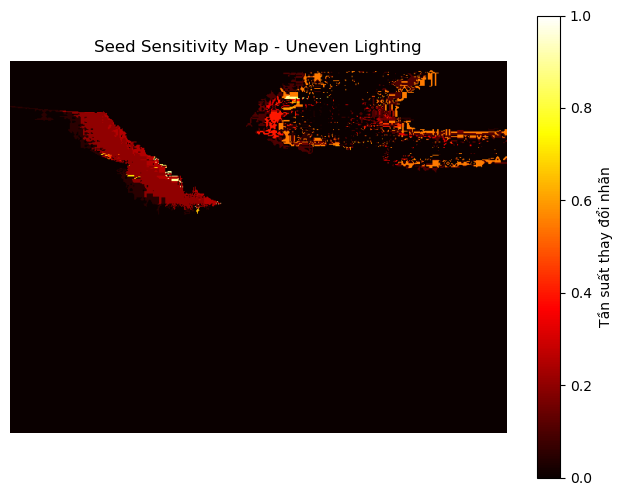

In [28]:
segment_fn = partial(
    region_growing_classic,
    T=5,
    order="stack"
)

sensitivity = seed_sensitivity(
    test_img,
    test_seeds,
    segment_fn,
    n_trials=20,
    jitter=3
)

print("Kích thước:", sensitivity.shape)
print("Kiểu dữ liệu:", sensitivity.dtype)
print("Giá trị nhỏ nhất:", sensitivity.min())
print("Giá trị lớn nhất:", sensitivity.max())
print("Số pixel có thay đổi nhãn:", np.count_nonzero(sensitivity))

assert sensitivity.shape == test_img.shape
assert sensitivity.dtype == np.float32
assert np.isfinite(sensitivity).all()
assert np.all((sensitivity >= 0) & (sensitivity <= 1))

print("Kiểm tra Seed Sensitivity: PASS")

plt.figure(figsize=(8, 6))
plt.imshow(sensitivity, cmap="hot", vmin=0, vmax=1)
plt.colorbar(label="Tần suất thay đổi nhãn")
plt.title("Seed Sensitivity Map - Uneven Lighting")
plt.axis("off")
plt.show()

**Khai báo hỗ trợ cho cell kiểm chứng Vòng 1**

- Công cụ: Trợ lý AI của OpenAI.
- Mục đích: Viết cell kiểm chứng dựa trên các ca thử Hiệp đề xuất cho trung bình vùng, nhãn chưa gán và seed nhiễu.
- Prompt nguyên văn:

> bạn cho tôi code đi tôi gợi ý cho bạn đó

In [29]:
import numpy as np
from functools import partial
from unittest.mock import patch


def kiem_tra_vong_1_sen():
    # Trung bình lần lượt là 0, 1, 5/3.
    # Pixel có giá trị 4 cách 5/3 hơn T=2 nên giữ nhãn -1.
    img = np.array([[0, 2, 3, 4]])
    expected_labels = np.array([[0, 0, 0, -1]], dtype=np.int32)

    for order in ("stack", "queue"):
        labels = region_growing_classic(img, [(0, 0)], T=2, order=order)
        np.testing.assert_array_equal(labels, expected_labels)
        assert labels.dtype == np.int32, f"{order}: labels phải là int32"

    # Nhiều seed: ba khối 30/120/210, mỗi seed giữ đúng ID theo thứ tự trong danh sách.
    blocks = np.repeat([30, 120, 210], 4)[None, :].repeat(8, axis=0)
    blocks = blocks + np.random.default_rng(0).integers(-1, 2, size=blocks.shape)
    block_seeds = [(4, 10), (4, 2), (4, 6)]
    expected_blocks = np.repeat([1, 2, 0], 4)[None, :].repeat(8, axis=0)
    for order in ("stack", "queue"):
        np.testing.assert_array_equal(
            region_growing_classic(blocks, block_seeds, T=3, order=order),
            expected_blocks,
        )

    segment = partial(region_growing_classic, T=2, order="stack")
    zero_map = seed_sensitivity(img, [(0, 0)], segment, n_trials=4, jitter=0)
    np.testing.assert_array_equal(zero_map, np.zeros(img.shape))

    def kiem_tra_seed_nhieu(shape, seeds, jitter):
        probe_img = np.zeros(shape, dtype=np.uint8)
        original_seeds = np.asarray(seeds)
        seen = []
        n_trials = 200

        def probe(image, trial_seeds):
            seen.append(np.asarray(trial_seeds).copy())
            trial = len(seen) - 1  # Lần gọi đầu là baseline.
            labels = np.zeros(image.shape, dtype=np.int32)

            if trial > 0:
                labels[0, 0] = 1
            if 1 <= trial <= n_trials // 2:
                labels[0, 1] = 1

            return labels, np.zeros(image.shape, dtype=bool)

        # Cố định RNG trong phép thử để chạy lại được cùng dãy seed.
        with patch.object(np.random, "default_rng", return_value=np.random.default_rng(0)):
            actual = seed_sensitivity(
                probe_img, seeds, probe, n_trials=n_trials, jitter=jitter
            )

        assert len(seen) == n_trials + 1, "Thiếu baseline hoặc lượt thử"
        np.testing.assert_array_equal(seen[0], original_seeds)

        for moved in seen[1:]:
            assert moved.shape == original_seeds.shape, "Số seed đã thay đổi"
            assert np.all((0 <= moved) & (moved < shape)), "Seed ra ngoài ảnh"
            assert len(np.unique(moved, axis=0)) == len(seeds), "Seed bị trùng"
            assert np.all(np.abs(moved - original_seeds) <= jitter), "Seed lệch quá jitter"

        assert any(np.any(moved != original_seeds) for moved in seen[1:]), (
            "Seed chưa từng dịch"
        )

        # Pixel đầu đổi nhãn mọi lượt, pixel thứ hai đổi nhãn nửa số lượt.
        expected_rate = np.zeros(shape, dtype=np.float32)
        expected_rate[0, :2] = (1.0, 0.5)
        np.testing.assert_array_equal(actual, expected_rate)

    # Seed ở góc để kiểm biên, seed sát nhau để kiểm trùng.
    kiem_tra_seed_nhieu((6, 8), [(0, 0), (5, 7)], jitter=3)
    kiem_tra_seed_nhieu((5, 5), [(2, 2), (2, 3)], jitter=1)

    print("ĐẠT: cập nhật trung bình, nhãn -1/int32, jitter=0, seed nhiễu và tỉ lệ đổi nhãn.")


kiem_tra_vong_1_sen()

ĐẠT: cập nhật trung bình, nhãn -1/int32, jitter=0, seed nhiễu và tỉ lệ đổi nhãn.


## Tích hợp với SRG của Hiệp

Thống nhất biểu diễn seeds và ID vùng. Dùng phiên bản SRG đã được duyệt khi kiểm chứng và đo seed_sensitivity; ghi nguồn/commit.

**Quy ước chung với SRG của Hiệp**

- **Seeds:** danh sách `[(row, col), ...]`, tọa độ nguyên, không trùng nhau, nằm trong ảnh.
- **ID vùng:** vùng của seed thứ `i` trong danh sách mang nhãn `i` (0, 1, 2, ...). Thứ tự danh sách là ID, không sắp xếp lại.
- **Pixel chưa gán:** `-1`, kiểu `int32` (chỉ có ở `region_growing_classic`; `srg` gán mọi pixel `>= 0`).
- **Seed rơi vào vùng đã mọc trước:** `region_growing_classic` bỏ qua seed đó, nên ID của nó không xuất hiện trong kết quả.
- **`seed_sensitivity`:** giữ nguyên thứ tự seed khi nhiễu, nên ID của lần thử khớp với baseline và so nhãn trực tiếp không cần căn chỉnh. Nếu `segment_fn` trả tuple (như `srg`) thì lấy phần tử đầu là bản đồ nhãn.
- **Phiên bản `srg` dùng để kiểm chứng:** nhánh `bt2-hiep`, commit `<điền khi Hiệp bàn giao>`.

In [6]:
from heapq import heappop, heappush
from random import Random

import numpy as np

TIE_RANDOM_SEED = 0  

def _parse_seeds(seeds, h, w):
    """Mỗi hạt giống là một pixel (row, col) hoặc một tập pixel [(row, col), ...]."""
    seed_sets = []
    for seed in seeds:
        arr = np.asarray(seed)
        if arr.ndim == 1:
            arr = arr.reshape(1, -1)
        if arr.ndim != 2 or arr.shape[1] != 2 or len(arr) == 0:
            raise ValueError("Mỗi seed phải là (row, col) hoặc danh sách (row, col)")
        if not np.issubdtype(arr.dtype, np.integer):
            raise ValueError("Tọa độ seed phải là số nguyên")
        points = [(int(r), int(c)) for r, c in arr]
        for r, c in points:
            if not (0 <= r < h and 0 <= c < w):
                raise ValueError("Seed nằm ngoài ảnh")
        seed_sets.append(points)
    return seed_sets


def _srg(img, seeds, connectivity, stale, tie, n_frames):
    img = np.asarray(img, dtype=float)
    if img.ndim != 2 or img.size == 0:
        raise ValueError("img phải là ảnh xám 2D không rỗng")
    if connectivity not in (4, 8):
        raise ValueError("connectivity phải là 4 hoặc 8")
    if stale not in ("lazy", "frozen"):
        raise ValueError("stale phải là lazy hoặc frozen")
    if tie not in ("insertion", "raster", "random"):
        raise ValueError("tie không hợp lệ")

    h, w = img.shape
    seed_sets = _parse_seeds(seeds, h, w)
    all_seed_points = [p for points in seed_sets for p in points]
    if not seed_sets or len(set(all_seed_points)) != len(all_seed_points):
        raise ValueError("Cần ít nhất một seed và các seed không được trùng pixel")

    offsets = [(-1, 0), (0, -1), (0, 1), (1, 0)]
    if connectivity == 8:
        offsets += [(-1, -1), (-1, 1), (1, -1), (1, 1)]

    labels = np.full((h, w), -1, dtype=np.int32)
    boundary = np.zeros((h, w), dtype=bool)
    seed_values = []
    totals = []
    counts = []
    for i, points in enumerate(seed_sets):
        for p in points:
            labels[p] = i
        values = [img[p] for p in points]
        seed_values.append(sum(values) / len(values))
        totals.append(sum(values))
        counts.append(len(values))

    heap = []
    queued = {}
    keys = {}
    rng = Random(TIE_RANDOM_SEED)
    frames = []
    filled = len(all_seed_points)

    def neighbors(r, c):
        for dr, dc in offsets:
            rr, cc = r + dr, c + dc
            if 0 <= rr < h and 0 <= cc < w:
                yield rr, cc

    def key(point):
        if point not in keys:
            if tie == "insertion":
                keys[point] = len(keys)
            elif tie == "raster":
                keys[point] = point[0] * w + point[1]
            else:
                keys[point] = rng.random()
        return keys[point]

    region_keys = [min(key(p) for p in points) for points in seed_sets]

    def candidate(point):
        regions = {
            int(labels[p]) for p in neighbors(*point) if labels[p] >= 0
        }
        value = img[point]
        options = []
        for i in regions:
            ref = seed_values[i] if stale == "frozen" else totals[i] / counts[i]
            options.append((abs(value - ref), region_keys[i], i))
        distance, _, region = min(options)
        return distance, region, len(regions) > 1

    def enqueue(point, distance):
        entry = (distance, key(point), point)
        if queued.get(point) != entry:
            queued[point] = entry
            heappush(heap, entry)

    def add_neighbors(point):
        for p in neighbors(*point):
            if labels[p] == -1:
                distance, _, _ = candidate(p)
                enqueue(p, distance)

    def save_frames():
        while len(frames) < n_frames and filled * n_frames >= (len(frames) + 1) * img.size:
            frames.append(labels.copy())

    for point in all_seed_points:
        add_neighbors(point)
    save_frames()

    while heap:
        entry = heappop(heap)
        old_distance, _, point = entry
        if queued.get(point) != entry:
            continue
        del queued[point]

        distance, region, is_boundary = candidate(point)
        if distance != old_distance:
            enqueue(point, distance)
            continue

        labels[point] = region
        boundary[point] = is_boundary
        totals[region] += img[point]
        counts[region] += 1
        filled += 1
        save_frames()
        add_neighbors(point)

    return labels, boundary, frames


def srg(img, seeds, connectivity=4, stale="lazy", tie="insertion"):
    """Seeded Region Growing (Adams & Bischof 1994), công thức (5). Dùng heapq.

    seeds: danh sách hạt giống; mỗi hạt giống là một pixel (row, col)
           hoặc một tập pixel [(row, col), ...]. Nhãn i ứng với seeds[i].
    stale: "lazy"   -> tính lại delta khi pop, đẩy lại nếu đã cũ
           "frozen" -> delta theo giá trị (trung bình) của hạt giống
    tie:   quy tắc phá hoà tất định: "insertion" | "raster" | "random"
           ("random" dùng seed cố định TIE_RANDOM_SEED)
    -> (labels, boundary_mask); mọi pixel đều có nhãn >= 0.
    """
    labels, boundary, _ = _srg(img, seeds, connectivity, stale, tie, 0)
    return labels, boundary

In [10]:
print("Hàm srg:", callable(srg))

Hàm srg: True


## Kiểm chứng cài đặt

Mã A1-A5 và B1-B5 bên dưới là thứ tự kiểm chứng trong mục 3.7 / 4.5 của đề. Điền dữ liệu kiểm tra, số đo và output thực tế. Các ô mã hiện để trống.

### Kiểm chứng B1 - Phân hoạch đầy đủ

Kiểm tra mọi labels của SRG >= 0. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [31]:
labels_srg, boundary_mask = srg(
    test_img,
    test_seeds,
    connectivity=4,
    stale="lazy",
    tie="insertion"
)

unassigned_count = np.count_nonzero(labels_srg < 0)

print("Image shape:", test_img.shape)
print("Labels shape:", labels_srg.shape)
print("Labels dtype:", labels_srg.dtype)
print("Các nhãn xuất hiện:", np.unique(labels_srg))
print("Unassigned pixels:", unassigned_count)
print("Boundary pixels:", np.count_nonzero(boundary_mask))

assert labels_srg.shape == test_img.shape
assert labels_srg.dtype == np.int32
assert boundary_mask.shape == test_img.shape
assert np.all(labels_srg >= 0)

print("B1: PASS")

Image shape: (480, 640)
Labels shape: (480, 640)
Labels dtype: int32
Các nhãn xuất hiện: [0 1]
Unassigned pixels: 0
Boundary pixels: 1045
B1: PASS


**Nhận xét kiểm chứng:**

- Kết quả thực tế: SRG phân hoạch toàn bộ ảnh thành 2 vùng, không còn pixel chưa được gán nhãn. Có 1.045 pixel biên.
- Đạt/chưa đạt và lý do: Đạt. Kích thước bản đồ nhãn khớp ảnh đầu vào, kiểu dữ liệu đúng int32 và tất cả pixel đều có nhãn hợp lệ.

### Kiểm chứng B2 - Số vùng

Kiểm tra số nhãn phân biệt bằng số hạt giống hợp lệ. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [32]:
# B2 - Kiểm chứng số vùng bằng số seed

num_regions = len(np.unique(labels_srg))
num_seeds = len(test_seeds)

print("Số seed:", num_seeds)
print("Số vùng thực tế:", num_regions)
print("Các nhãn:", np.unique(labels_srg))

assert num_regions == num_seeds

print("B2: PASS")

Số seed: 2
Số vùng thực tế: 2
Các nhãn: [0 1]
B2: PASS


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Có 2 seed và 2 vùng được tạo ra, tương ứng nhãn 0 và 1.
- Đạt/chưa đạt và lý do: Đạt. Số vùng thực tế bằng số seed ban đầu.

### Kiểm chứng B3 - Đảo thứ tự hạt giống

So kết quả sau khi thống nhất lại ý nghĩa ID nhãn; ghi quy tắc phá hòa. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [33]:
# B3 - Kiểm chứng đảo thứ tự hạt giống

reversed_seeds = list(reversed(test_seeds))

labels_reversed, boundary_reversed = srg(
    test_img,
    reversed_seeds,
    connectivity=4,
    stale="lazy",
    tie="insertion"
)

# Đổi ID nhãn về thứ tự seed ban đầu để so sánh công bằng
labels_reversed_mapped = np.full_like(labels_reversed, -1)

num_seeds = len(test_seeds)

for new_id in range(num_seeds):
    old_id = num_seeds - 1 - new_id
    labels_reversed_mapped[labels_reversed == new_id] = old_id

changed_pixels = np.count_nonzero(
    labels_srg != labels_reversed_mapped
)

total_pixels = labels_srg.size
changed_ratio = changed_pixels / total_pixels * 100

print("Số pixel thay đổi:", changed_pixels)
print("Tỷ lệ pixel thay đổi: {:.4f}%".format(changed_ratio))
print("Kết quả giống nhau:", changed_pixels == 0)

print("B3: DONE")

Số pixel thay đổi: 0
Tỷ lệ pixel thay đổi: 0.0000%
Kết quả giống nhau: True
B3: DONE


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Sau khi đảo thứ tự hai seed và quy đổi ID nhãn về thứ tự ban đầu, có 0 pixel thay đổi.
- Đạt/chưa đạt và lý do: Đạt. Kết quả phân vùng không thay đổi khi đảo thứ tự seed trong thí nghiệm này.

### Kiểm chứng B4 - Stack, queue và SRG

Cùng ảnh, cùng seeds; báo số pixel khác nhau trong từng cặp. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [35]:
# B4 - So sánh Region Growing và SRG

labels_stack = region_growing_classic(
    test_img, test_seeds, T=T_test, order="stack"
)

labels_queue = region_growing_classic(
    test_img, test_seeds, T=T_test, order="queue"
)

labels_srg, boundary_mask = srg(
    test_img,
    test_seeds,
    connectivity=4,
    stale="lazy",
    tie="insertion"
)

diff_stack_queue = np.count_nonzero(labels_stack != labels_queue)
diff_stack_srg = np.count_nonzero(labels_stack != labels_srg)
diff_queue_srg = np.count_nonzero(labels_queue != labels_srg)

print("Stack vs Queue:", diff_stack_queue, "pixel")
print("Stack vs SRG:", diff_stack_srg, "pixel")
print("Queue vs SRG:", diff_queue_srg, "pixel")

print("B4: DONE")

Stack vs Queue: 9773 pixel
Stack vs SRG: 188649 pixel
Queue vs SRG: 186944 pixel
B4: DONE


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Số pixel khác nhau giữa Stack và Queue là 9.773 pixel; giữa Stack và SRG là 188.649 pixel; giữa Queue và SRG là 186.944 pixel.
- Đạt/chưa đạt và lý do: Đạt. Ba phương pháp cho kết quả phân vùng khác nhau. Stack và Queue có sự khác biệt do thứ tự duyệt pixel ảnh hưởng đến quá trình phát triển vùng. SRG có kết quả khác biệt lớn hơn vì cơ chế phát triển nhiều vùng đồng thời và gán nhãn toàn bộ pixel.

## Thí nghiệm - B: Region Growing đối chiếu SRG; độ nhạy hạt giống

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



## Bàn giao cho nhóm trưởng

- [ ] Đúng giao diện hàm và quy ước tọa độ.
- [ ] Restart & Run All chạy được, đã lưu output.
- [ ] Ảnh cần dùng có trong images/ tại gốc repo; dùng IMAGES_DIR để đọc ảnh.
- [ ] Kiểm chứng và thí nghiệm có số đo thực tế.
- [ ] Cell thí nghiệm có dùng AI ghi đúng prompt ngay phía trên.
- [ ] Đã mở Pull Request và ghi nguồn các hàm dùng chung.